# Learned Representations and Transfer Learning - Solution


**Business problem:** categorize clothing images with limited target training labels. Compare raw pixels plus a linear head
with frozen ResNet-18 features plus the same type of head. Fashion-MNIST is a benchmark, not representative shop photography.

In this notebook, we will:
1. Preserve the official data boundary and reproduce a balanced target-label budget.
2. Freeze a pretrained encoder correctly and train a small classification head.
3. Select models using validation only and compare against raw-pixel and guessing baselines.
4. Interpret category errors, domain mismatch and operational costs.

**SW07 Lecture 4 companion. Prerequisites:** CNNs, classification, loss and validation from Lectures 1-3.
This is supervised transfer learning, not an autoencoder or an unsupervised training exercise.
One prepared-results comparison fits the lecture's 10-minute slot. The full sequence is a separate approximately 60-minute practical,
plus cold feature extraction and any pretrained-weight download. Precompute features before class; do not compress cold execution into 45 minutes.
Keep 5,000 training, 5,000 validation and 5,000 official test images; train heads for at most 30 epochs with the supplied stopping rule.


This is the completed companion to the [exercise](transfer_learning_exercise.ipynb). Read the [concepts](transfer_learning_concept.ipynb) first. Numbered steps, settings and code match the exercise. Try each interpretation before expanding its worked answer.

## Libraries and reproducibility

Use [the pinned PyTorch requirements](../requirements-transfer-learning-pytorch.txt) in a separate environment:
`pip install -r ../requirements-transfer-learning-pytorch.txt` from this directory.
Images and labels must exist in `../../../00_Data/FashionMNIST/raw/`; dataset downloads are disabled.
See [the repository's data documentation](../../../README.md#fashion-mnist-image-data) if files must be prepared.
The pinned Microsoft ResNet-18 weights and processor are a separate first-use download in Hugging Face's cache. Only safetensors weights are loaded; no custom remote model code is used.
Feature caches are generated under `00_Data/resnet18-transformers-features/`, not source data or independent results.

This trio needs neither torchvision nor TensorFlow. Use Python 3.11 with the pinned versions.
The encoder uses Apple MPS if available, otherwise CPU. Heads train on CPU. Seeds, versions and cache keys are explicit;
small device/version differences remain possible. This is the same controlled five-category comparison throughout.

In [1]:
import importlib.metadata
from copy import deepcopy
from hashlib import sha256
from pathlib import Path
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoImageProcessor, ResNetModel
from fashion_mnist_data import load_fashion_partition

SEED = 7
BATCH_SIZE = 64
HEAD_EPOCHS = 30
DATA_ROOT = Path('../../../00_Data').resolve()
DEVICE = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
MODEL_ID = 'microsoft/resnet-18'
MODEL_REVISION = '65a5785d9156231087c481e0c7dd33a5ff6f7e3e'
TARGET_CLASS_IDS = (1, 5, 7, 8, 9)
CLASS_NAMES = ['Trouser', 'Sandal', 'Sneaker', 'Bag', 'Ankle boot']
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
print('Data directory:', DATA_ROOT)
print('PyTorch:', torch.__version__, '| CNN device:', DEVICE, '| seed:', SEED)
print({name: importlib.metadata.version(name)
       for name in ['torch', 'transformers', 'huggingface-hub', 'safetensors', 'Pillow', 'numpy', 'pandas', 'scikit-learn', 'matplotlib']})

/private/tmp/zhaw-transfer-pytorch-no-torchvision/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Data directory: /Users/iaracena/VisualStudioProjects/ZHAW/python_machine_learning_basics/00_Data
PyTorch: 2.2.2 | CNN device: mps | seed: 7
{'torch': '2.2.2', 'transformers': '4.40.2', 'huggingface-hub': '0.23.4', 'safetensors': '0.4.5', 'Pillow': '10.4.0', 'numpy': '1.26.4', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'matplotlib': '3.9.4'}


## 1. Prepare image tensors and remap targets

Load official training images only. Use the supplied seed-7 stratified splits to select balanced training and validation partitions.
Map Fashion-MNIST class IDs `(1, 5, 7, 8, 9)` to consecutive outputs `0, 1, 2, 3, 4` using `torch.arange(5)`.
Divide each pixel by 255. This fixed scaling fits no statistics on validation or test images.
The training grid is not chosen for model successes. The test images stay unloaded until Step 5.

Training / validation images: 5000 / 5000


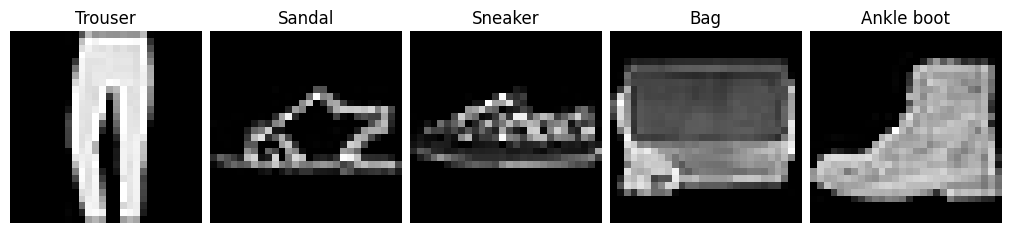

In [2]:
official_train_images, labels = load_fashion_partition(DATA_ROOT, training=True)
target_indices = np.flatnonzero(np.isin(labels, TARGET_CLASS_IDS))
training_pool, validation_indices = train_test_split(target_indices, test_size=5000, stratify=labels[target_indices], random_state=SEED)
training_indices, _ = train_test_split(training_pool, train_size=5000, stratify=labels[training_pool], random_state=SEED)
label_map = torch.full((10,), -1, dtype=torch.long)
label_map[list(TARGET_CLASS_IDS)] = torch.arange(5)
train_images = torch.from_numpy(official_train_images[training_indices]).float().unsqueeze(1) / 255.0
validation_images = torch.from_numpy(official_train_images[validation_indices]).float().unsqueeze(1) / 255.0
train_targets = label_map[torch.as_tensor(labels[training_indices], dtype=torch.long)]
validation_targets = label_map[torch.as_tensor(labels[validation_indices], dtype=torch.long)]
print('Training / validation images:', len(train_images), '/', len(validation_images))

figure, axes = plt.subplots(1, 5, figsize=(10, 3), layout='constrained')
for category, axis in enumerate(axes):
    position = int(torch.nonzero(train_targets == category)[0].item())
    axis.imshow(train_images[position, 0], cmap='gray', vmin=0, vmax=1)
    axis.set_title(CLASS_NAMES[category])
    axis.axis('off')
plt.show()

Why must the five original category IDs be remapped, and what annotation costs are omitted by the phrase 5,000 training labels?

<details>
<summary>Answer and self-check</summary>

**Answer:** The head has five outputs indexed 0-4; targets must use those indices rather than IDs up to 9. Target validation labels and labels used in balanced sampling are additional requirements. ImageNet pretraining also used labels and computation.

**Intermediate:** 3 points: valid target indices (1); validation/sampling labels (1); external pretraining (1).

**Common mistake:** Calling this an unsupervised learning experiment because the encoder is frozen.

</details>

## 2. Establish guessing and raw-pixel baselines

Always predict the most common training category; balanced validation gives 20% accuracy.
Train a linear head on all 784 pixels using the supplied `train_head` helper.
Its training uses only training labels. Validation chooses the best accuracy checkpoint, with a maximum of 30 epochs
and stopping after five epochs without a strict improvement. Restore that saved checkpoint, not the final epoch's weights.
Ties in validation accuracy do not replace the earlier checkpoint.

In [3]:
majority_class = int(torch.bincount(train_targets).argmax())
prior_validation = (validation_targets == majority_class).float().mean().item()
print('Guess-one-category validation accuracy:', f'{prior_validation:.1%}')

Guess-one-category validation accuracy: 20.0%


In [4]:
def train_head(training_features, validation_features):
    torch.manual_seed(SEED)
    head = nn.Linear(training_features.shape[1], 5)
    optimizer = torch.optim.Adam(head.parameters(), lr=0.001)
    loader = DataLoader(TensorDataset(training_features, train_targets), batch_size=256, shuffle=True, generator=torch.Generator().manual_seed(SEED))
    best_accuracy, best_epoch = -1.0, 0
    best_weights = deepcopy(head.state_dict())
    for epoch in range(1, HEAD_EPOCHS + 1):
        head.train()
        for inputs, targets in loader:
            optimizer.zero_grad()
            loss = nn.functional.cross_entropy(head(inputs), targets)
            loss.backward()
            optimizer.step()
        head.eval()
        with torch.no_grad():
            predicted = head(validation_features).argmax(dim=1)
            accuracy = (predicted == validation_targets).float().mean().item()
        if accuracy > best_accuracy:
            best_accuracy, best_epoch = accuracy, epoch
            best_weights = deepcopy(head.state_dict())
        if epoch - best_epoch >= 5:
            break
    head.load_state_dict(best_weights)
    print(f'Selected epoch {best_epoch}; validation accuracy {best_accuracy:.1%}')
    return head, best_accuracy

pixel_head, pixel_validation = train_head(train_images.flatten(1), validation_images.flatten(1))

Selected epoch 30; validation accuracy 93.5%


Why compare with a trainable pixel head instead of reporting only the 20% guessing rule?

<details>
<summary>Answer and self-check</summary>

**Answer:** It measures how useful the target pixels and labels already are without a pretrained representation. It uses the same target training examples and selection rule, but its smaller pipeline does not incur the same compute or external pretraining cost.

**Intermediate:** 2 points: stronger same-label baseline (1); distinguish target-label parity from equal total cost (1).

**Common mistake:** Assuming 20% chance performance means any pretrained pipeline is operationally justified.

</details>

## 3. Reuse a frozen encoder and cache its features

Transformers supplies the pretrained PyTorch `ResNetModel` without the ImageNet classifier; its pooled output exposes 512 features.
Despite the library name, this is a CNN, not a transformer architecture. The model revision and processor are pinned together.
Set `requires_grad_` to `False` so encoder parameters are not trained. The supplied `eval()` additionally fixes batch-normalization state.
Repeating a grayscale channel adds no image information. Use the selected weights' prescribed resizing, cropping and normalization.
Feature extraction is image-wise and fits no target validation/test statistics.

Cache keys include images, preprocessing, weights, device and package versions. Loading a cache does not train the CNN. NumPy files load with `allow_pickle=False`; old torchvision and Keras caches are not interchangeable.
Do not reuse those feature arrays as though they allow gradient-based fine-tuning of the encoder.

In [5]:
preprocess = AutoImageProcessor.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
encoder = ResNetModel.from_pretrained(MODEL_ID, revision=MODEL_REVISION, use_safetensors=True)
encoder.requires_grad_(False)
encoder.to(DEVICE).eval()
feature_count = encoder.config.hidden_sizes[-1]
print('Features per image:', feature_count)

FEATURE_CACHE = DATA_ROOT / 'resnet18-transformers-features'
FEATURE_CACHE.mkdir(parents=True, exist_ok=True)
weight_digest = sha256()
for name, value in encoder.state_dict().items():
    weight_digest.update(name.encode() + value.detach().cpu().numpy().tobytes())
recipe = json.dumps({
    'model': MODEL_ID,
    'revision': MODEL_REVISION,
    'weights_sha256': weight_digest.hexdigest(),
    'preprocessing': preprocess.to_dict(),
    'input_conversion': '0-1 grayscale to rounded 0-255 uint8, repeat three channels',
    'device': str(DEVICE),
    'versions': {name: importlib.metadata.version(name)
                 for name in ['torch', 'transformers', 'huggingface-hub', 'Pillow', 'numpy']},
}, sort_keys=True)


def extract_features(images):
    identity = f'{recipe}|{tuple(images.shape)}|{images.dtype}'
    key = sha256(identity.encode() + images.numpy().tobytes()).hexdigest()
    cache_path = FEATURE_CACHE / f'{key}.npz'
    if cache_path.exists():
        with np.load(cache_path, allow_pickle=False) as cached:
            features = torch.from_numpy(cached['features'])
        assert features.shape == (len(images), feature_count) and torch.isfinite(features).all()
        print('Using cached features for', len(images), 'images')
        return features
    started = time.monotonic()
    batches = []
    encoder.eval()
    with torch.no_grad():
        for position, batch in enumerate(images.split(BATCH_SIZE)):
            rgb_images = batch.repeat(1, 3, 1, 1).mul(255).round().to(torch.uint8).numpy()
            inputs = preprocess(images=list(rgb_images), return_tensors='pt')['pixel_values'].to(DEVICE)
            batches.append(encoder(pixel_values=inputs).pooler_output.flatten(1).cpu())
            if (position + 1) % 20 == 0:
                print('Images processed:', min((position + 1) * BATCH_SIZE, len(images)), '/', len(images), flush=True)
    features = torch.cat(batches)
    assert features.shape == (len(images), feature_count) and torch.isfinite(features).all()
    np.savez_compressed(cache_path, features=features.numpy())
    print(f'Extracted {len(images):,} images in {time.monotonic() - started:.1f} seconds')
    return features

train_features = extract_features(train_images)
validation_features = extract_features(validation_images)
print('Training feature matrix:', tuple(train_features.shape))

/private/tmp/zhaw-transfer-pytorch-no-torchvision/lib/python3.11/site-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Could not find image processor class in the image processor config or the model config. Loading based on pattern matching with the model's feature extractor configuration. Please open a PR/issue to update `preprocessor_config.json` to use `image_processor_type` instead of `feature_extractor_type`. This warning will be removed in v4.40.


Features per image: 512


Images processed: 1280 / 5000


Images processed: 2560 / 5000


Images processed: 3840 / 5000


Extracted 5,000 images in 33.8 seconds


Images processed: 1280 / 5000


Images processed: 2560 / 5000


Images processed: 3840 / 5000


Extracted 5,000 images in 32.9 seconds
Training feature matrix: (5000, 512)


What different purposes do freezing parameters and calling eval() serve? When would cached features become invalid?

<details>
<summary>Answer and self-check</summary>

**Answer:** Freezing prevents gradient-based encoder parameter updates; eval fixes evaluation behavior, including batch-normalization statistics. Changing weights, images or preprocessing changes the mapping. Old feature arrays cannot provide encoder gradients for fine-tuning.

**Intermediate:** 3 points: parameter freeze (1); model state/evaluation mode (1); cache invalidation and missing gradients (1).

**Common mistake:** Assuming requires_grad_(False) automatically puts the model in evaluation mode.

</details>

## 4. Train the new head and choose a pipeline

Train `Linear(512, 5)` on the frozen features using the same helper as the pixel head.
Count the head parameters with `(feature_count + 1) * len(CLASS_NAMES)`: one weight per feature/output pair and one bias per output.
Only this head's 2,565 weights and biases change. The cross-entropy implementation is supplied, not a code gap. PyTorch cross-entropy consumes logits and integer targets; no softmax is added before it.
Select the model name with the **highest validation accuracy**, using `validation_results.idxmax()`.
A tie selects the first supplied pipeline. Test results play no part in this choice.

In [6]:
resnet_head, resnet_validation = train_head(train_features, validation_features)
validation_results = pd.Series({'Raw pixels + head': pixel_validation, 'Frozen ResNet-18 + head': resnet_validation}, name='Validation accuracy')
selected_model = validation_results.idxmax()
head_parameter_count = (feature_count + 1) * len(CLASS_NAMES)
print('Model chosen using validation images:', selected_model)
display((100 * validation_results).rename('Validation accuracy (%)').round(2).to_frame())
print('Trainable weights and biases in the ResNet head:', head_parameter_count)
assert head_parameter_count == sum(parameter.numel() for parameter in resnet_head.parameters())

Selected epoch 29; validation accuracy 96.1%
Model chosen using validation images: Frozen ResNet-18 + head


,Validation accuracy (%)
Raw pixels + head,93.46
Frozen ResNet-18 + head,96.10


Trainable weights and biases in the ResNet head: 2565


Which model does validation select, and does that comparison isolate the causal effect of pretraining?

<details>
<summary>Answer and self-check</summary>

**Answer:** Report the name returned by validation_results.idxmax() and the observed percentage-point accuracy gap. It compares full pipelines with different resizing/cropping and representations, so it does not isolate pretraining alone or establish a causal business effect.

**Intermediate:** 3 points: measured validation choice (1); percentage-point comparison (1); qualified full-pipeline interpretation (1).

**Common mistake:** Assuming pretrained features must outperform pixels or choosing from test accuracy.

</details>

## 5. Evaluate fixed choices on official test images

Only now load all 5,000 official test images in the five categories.
Compute accuracy for guessing, pixels and frozen features. Preserve the validation-selected pipeline even if test rankings differ.
These are historical benchmark observations. Do not retune the encoder, label budget or head using these test results.

In [7]:
official_test_images, official_test_labels = load_fashion_partition(DATA_ROOT, training=False)
test_indices = np.flatnonzero(np.isin(official_test_labels, TARGET_CLASS_IDS))
test_images = torch.from_numpy(official_test_images[test_indices]).float().unsqueeze(1) / 255.0
test_targets = label_map[torch.as_tensor(official_test_labels[test_indices], dtype=torch.long)]
test_features = extract_features(test_images)
with torch.no_grad():
    test_predictions = {
        'Guess one category': np.full(len(test_targets), int(torch.bincount(train_targets).argmax())),
        'Raw pixels + head': pixel_head(test_images.flatten(1)).argmax(dim=1).numpy(),
        'Frozen ResNet-18 + head': resnet_head(test_features).argmax(dim=1).numpy(),
    }
test_results = pd.Series({name: 100 * accuracy_score(test_targets.numpy(), predicted) for name, predicted in test_predictions.items()}, name='Test accuracy (%)')
display(test_results.round(2).to_frame())
print('Validation-selected model:', selected_model)
print('Selected model test accuracy:', f'{test_results[selected_model]:.2f}%')

Images processed: 1280 / 5000


Images processed: 2560 / 5000


Images processed: 3840 / 5000


Extracted 5,000 images in 34.3 seconds


,Test accuracy (%)
Guess one category,20.00
Raw pixels + head,93.56
Frozen ResNet-18 + head,95.76


Validation-selected model: Frozen ResNet-18 + head
Selected model test accuracy: 95.76%


How much better or worse is the selected model than each baseline, and how should a test/validation rank reversal be handled?

<details>
<summary>Answer and self-check</summary>

**Answer:** Use the executed test table and calculate percentage-point differences. Keep the validation-selected pipeline. A rank reversal signals uncertainty, not permission to pick from the test set. Further redesign needs fresh independent evaluation.

**Intermediate:** 3 points: use actual test evidence (1); correct percentage-point units (1); protect selection boundary (1).

**Common mistake:** Reporting a universal winning representation from one seed and one target-label budget.

</details>

## 6. Interpret category errors

The matrix reports errors for the validation-selected model. Rows are true categories; columns are predictions.
The image grid shows the first official test example of each category, not examples selected for correctness.
This is prediction inspection, not an explanation of causal pixels or customer behavior.
The 512 coordinates have no guaranteed names such as sleeve length or shoe height.

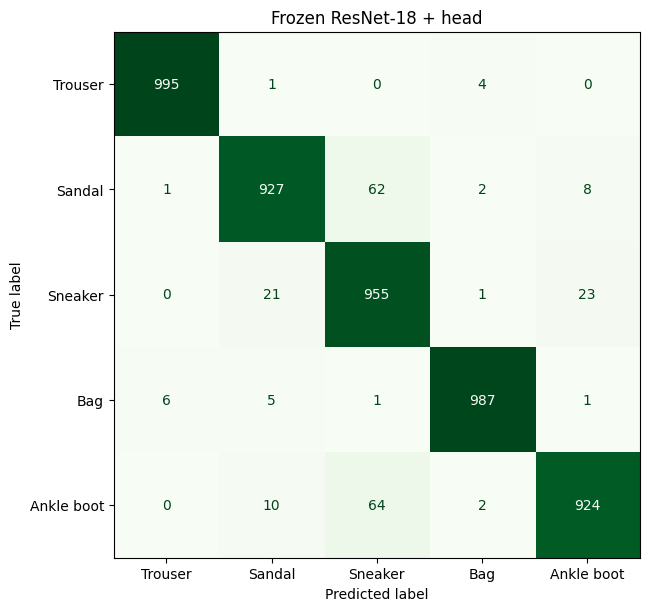

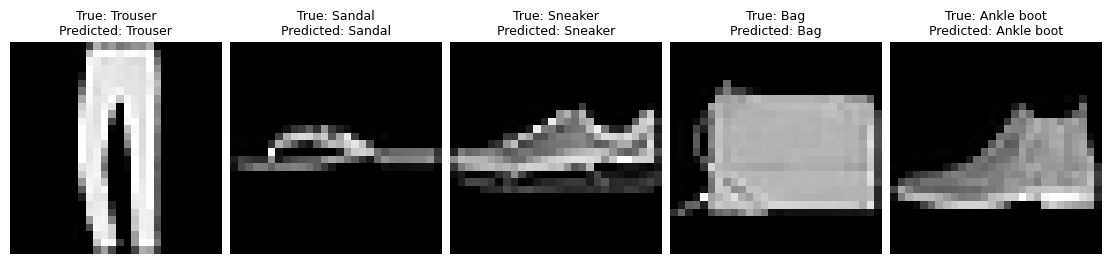

In [8]:
selected_predictions = test_predictions[selected_model]
figure, axis = plt.subplots(figsize=(7, 6), layout='constrained')
ConfusionMatrixDisplay.from_predictions(test_targets.numpy(), selected_predictions, display_labels=CLASS_NAMES, values_format='d', colorbar=False, cmap='Greens', ax=axis)
axis.set_title(selected_model)
plt.show()

figure, axes = plt.subplots(1, 5, figsize=(11, 3), layout='constrained')
for category, axis in enumerate(axes):
    position = int(torch.nonzero(test_targets == category)[0].item())
    axis.imshow(test_images[position, 0], cmap='gray', vmin=0, vmax=1)
    axis.set_title(f'True: {CLASS_NAMES[category]}\nPredicted: {CLASS_NAMES[selected_predictions[position]]}', fontsize=9)
    axis.axis('off')
plt.show()

Identify one observed category confusion. What would the shop need to measure before accepting that error pattern?

<details>
<summary>Answer and self-check</summary>

**Answer:** Use an actual off-diagonal matrix entry and its direction. Connect it to catalog routing, search experience or correction workload under explicit assumptions. Representative product photos and category-specific business costs are required before deployment.

**Intermediate:** 3 points: measured confusion and direction (1); explicit operational impact (1); representative evidence (1).

**Common mistake:** Treating example predictions as feature attributions or inventing a financial benefit.

</details>

## Business implications and limitations

- Benchmark images, ImageNet pretraining and real catalog photos are different domains. Resizing cannot restore missing details.
- Five thousand is the target training-label budget, not total labels, pretraining cost or total compute.
- This is one seed and one budget. Different preprocessing means the comparison does not isolate pretraining alone.
- Fixed-model feature caching saves repeated extraction, but storing and computing features still costs time and space.
- Model scores and unnamed features describe associations, not causal effects on catalog performance.
- Review rights to target and pretraining data, possible overlap, privacy, latency, category errors and monitoring before use.

Would you replace a shop system with this pipeline? Give a qualified recommendation and the next evaluation you would run.

<details>
<summary>Answer and self-check</summary>

**Answer:** Make a recommendation conditional on the measured baseline comparison, not on an assumed ResNet advantage. Test representative independently collected photos, measure category-specific correction costs, latency and search/routing outcomes, review data rights and establish human oversight and monitoring.

**Intermediate:** 3 points: observed evidence (1); representative business/cost evaluation (1); governance and monitoring (1).

**Common mistake:** Equating historical benchmark accuracy with guaranteed catalog quality or unsupervised learning.

</details>

## Summary and optional exercises

- Frozen transfer learning learns a new supervised head on a fixed representation; it is not an autoencoder.
- Compare against both guessing and raw pixels under the same target labels and validation rule.
- Cache fixed features, not a changing fine-tuned encoder; keep test results out of redesign.

**Optional practical:** compare a smaller, balanced subset of the current training indices, keeping validation fixed.
**Advanced practical:** fine-tune part of the CNN with a lower learning rate and a separate image-level training loop.
Cached arrays are no substitute for that loop. These activities belong outside the 10-minute lecture demonstration.
Plan fresh evaluation before using historical test findings to guide improvements.

## References

**Required student source:** Zalando Research. *Fashion-MNIST*: dataset, class labels and data license.
https://github.com/zalandoresearch/fashion-mnist

**Official technical documentation:** [Transformers 4.40.2 PyTorch ResNet](https://huggingface.co/docs/transformers/v4.40.2/model_doc/resnet),
[the pinned Microsoft ResNet-18 checkpoint](https://huggingface.co/microsoft/resnet-18/tree/65a5785d9156231087c481e0c7dd33a5ff6f7e3e),
[PyTorch transfer-learning tutorial](https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html),
[CrossEntropyLoss](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html).

**Optional instructor reference:** He, K., Zhang, X., Ren, S., & Sun, J. (2016).
*Deep Residual Learning for Image Recognition*. CVPR. https://arxiv.org/abs/1512.03385

**Required conceptual reading:** James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023).
*An Introduction to Statistical Learning: With Applications in Python*. Springer. Neural-network material.
https://www.statlearning.com/

**Environment:** [Pinned PyTorch requirements](../requirements-transfer-learning-pytorch.txt).
Transformers provides the PyTorch encoder and its image processor; torchvision and TensorFlow are not required.
The comparison uses results from the executed cells, not earlier torchvision/Keras runs or published ImageNet scores.

### Jupyter notebook - footer info

Include this information when submitting your notebook.

In [9]:
import platform
from datetime import datetime

print(platform.platform())
print('Python:', platform.python_version())
print('Date:', datetime.now().isoformat(timespec='seconds'))

macOS-26.6.2-arm64-i386-64bit
Python: 3.11.11
Date: 2026-10-25T22:53:46
